# 1989 — Convolutional Networks (LeNet)

**Papers:** Yann LeCun et al., *"Backpropagation Applied to Handwritten Zip Code Recognition"* (1989); *"Gradient-Based Learning Applied to Document Recognition"* (LeNet-5, 1998). Inspired by Fukushima's *Neocognitron* (1980).

Ideas that make images tractable:
- **Local receptive fields:** each unit sees a small patch.
- **Weight sharing:** the same filter slides over the whole image, so features are translation-equivariant and parameters are few.
- **Subsampling (pooling):** build tolerance to small shifts.

We build LeNet-5 (32×32 input → C1 → S2 → C3 → S4 → C5 → F6 → output) and train it on handwritten digits upscaled to 32×32. From here on, notebooks use PyTorch and **run on a GPU if one is available** (CUDA or Apple MPS), otherwise CPU.

![Diagram: LeNet-5 (LeCun et al., 1989/1998)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/10_1989_lenet_cnn.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]

Xtr, ytr, Xte, yte = load_digits_tensors(size=32)
Xtr, ytr, Xte, yte = Xtr.to(device), ytr.to(device), Xte.to(device), yte.to(device)
print(Xtr.shape, Xte.shape)

torch.Size([1437, 1, 32, 32]) torch.Size([360, 1, 32, 32])


In [3]:
class LeNet5(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5)       # 32 -> 28
        self.s2 = nn.AvgPool2d(2)          # 28 -> 14
        self.c3 = nn.Conv2d(6, 16, 5)      # 14 -> 10
        self.s4 = nn.AvgPool2d(2)          # 10 -> 5
        self.c5 = nn.Conv2d(16, 120, 5)    # 5 -> 1
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, n_classes)

    def forward(self, x):
        x = self.s2(torch.tanh(self.c1(x)))
        x = self.s4(torch.tanh(self.c3(x)))
        x = torch.tanh(self.c5(x)).flatten(1)
        return self.out(torch.tanh(self.f6(x)))

model = LeNet5().to(device)
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

LeNet5(
  (c1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (s2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (s4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c5): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (out): Linear(in_features=84, out_features=10, bias=True)
)
parameters: 61706


In [4]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
hist = []
for epoch in range(15):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    for i in range(0, len(Xtr), 64):
        idx = perm[i:i + 64]
        loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    hist.append((accuracy(model, Xtr, ytr), accuracy(model, Xte, yte)))
    if epoch % 3 == 2: print(f"epoch {epoch + 1:2d}  train {hist[-1][0]:.3f}  test {hist[-1][1]:.3f}")

epoch  3  train 0.913  test 0.889


epoch  6  train 0.969  test 0.936


epoch  9  train 0.986  test 0.956


epoch 12  train 0.992  test 0.964


epoch 15  train 0.997  test 0.967


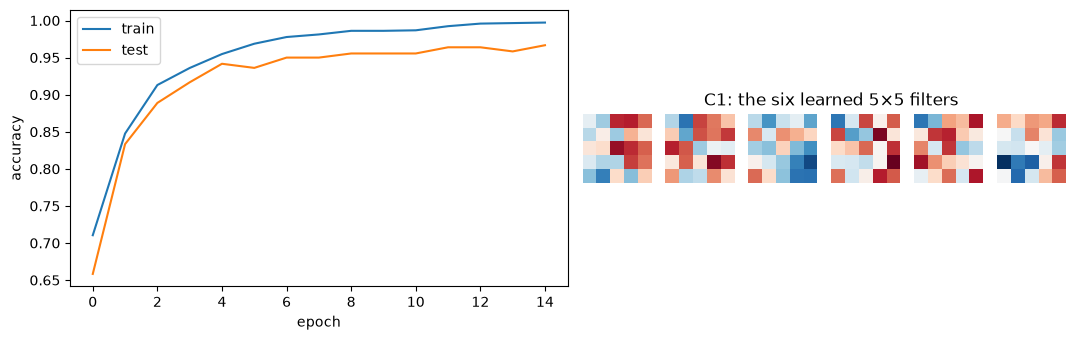

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot([h[0] for h in hist], label="train"); axes[0].plot([h[1] for h in hist], label="test")
axes[0].set(xlabel="epoch", ylabel="accuracy"); axes[0].legend()
w = model.c1.weight.detach().cpu()[:, 0]
grid = torch.cat([torch.cat([w[i], torch.full((5, 1), float("nan"))], 1) for i in range(6)], 1)
axes[1].imshow(grid, cmap="RdBu"); axes[1].set_title("C1: the six learned 5×5 filters"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## Feature maps and translation tolerance
The C1 maps show edge/stroke detectors. Convolutions are translation-*equivariant* and pooling adds some *local* invariance, but it is limited: small shifts cost a little accuracy, large ones a lot. That is why later CNNs (2012) added **data augmentation** with random shifts.

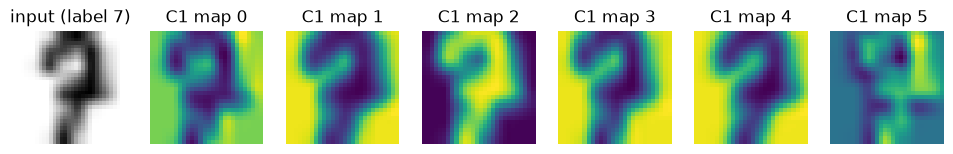

shift right by 0px -> test accuracy 0.967
shift right by 2px -> test accuracy 0.878
shift right by 4px -> test accuracy 0.500


In [6]:
x = Xte[:1]
with torch.no_grad():
    maps = torch.tanh(model.c1(x))[0].cpu()
fig, axes = plt.subplots(1, 7, figsize=(12, 2))
axes[0].imshow(x[0, 0].cpu(), cmap="gray_r"); axes[0].set_title(f"input (label {yte[0].item()})")
for i in range(6): axes[i + 1].imshow(maps[i], cmap="viridis"); axes[i + 1].set_title(f"C1 map {i}")
for a in axes: a.axis("off")
plt.show()

model.eval()
with torch.no_grad():
    for shift in [0, 2, 4]:
        acc = (model(torch.roll(Xte, shifts=shift, dims=3)).argmax(1) == yte).float().mean().item()
        print(f"shift right by {shift}px -> test accuracy {acc:.3f}")